# Taller — Construye y ajusta tu propio clasificador de imágenes

Este taller comienza **después de la teoría de CNN y del notebook guiado de transfer learning**.

La meta no es memorizar la API de Keras. La meta es tomar decisiones sobre un problema real: construir datos propios, adaptar un modelo preentrenado y analizar qué tan bien funciona.

---

## Organización de la actividad

| Momento | Tiempo estimado | Meta |
|---|---:|---|
| **Teoría + notebook guiado** | Se realiza antes de este taller | Comprender CNN, transfer learning y fine-tuning |
| **Trabajo en clase** | ~60 min | Construir el dataset y entrenar el primer modelo con la base congelada |
| **Trabajo en casa** | ~1–2 h | Evaluar, hacer fine-tuning, comparar y analizar errores |

### Regla importante

Durante el trabajo en clase usaremos **train** y **validation**.  
El conjunto de **test** se reservará para el trabajo en casa, cuando hagamos la evaluación final.

---

## Entrega final

Debes entregar **este mismo notebook ejecutado**, incluyendo:

- definición del problema y estrategia de búsqueda;
- dataset propio;
- primer entrenamiento con transfer learning;
- evaluación en test;
- fine-tuning;
- comparación antes/después;
- matriz de confusión;
- análisis de al menos 5 errores;
- conclusiones.

## 0. Preparación del entorno

La búsqueda de imágenes se realizará con `ddgs`. Si estás en Google Colab, ejecuta la siguiente celda.

In [10]:
!pip -q install -U ddgs

In [11]:
import os #Gestionar variables de entorno y aspectos del sistema.
os.environ["KERAS_BACKEND"] = "tensorflow"

from pathlib import Path #Trabajar con carpetas y archivos.
import hashlib, io, random, shutil, time #Identificar imágenes duplicadas mediante hashes, Realizar selecciones aleatorias, Organizar y copiar archivos.
import numpy as np #Trabajar con arreglos numéricos.
import matplotlib.pyplot as plt
import requests #Descargar imágenes desde Internet.
from PIL import Image #Leer y procesar imágenes.

import tensorflow as tf #Ejecutar operaciones de aprendizaje automático.
import keras #Construir y entrenar el modelo.
from keras import layers
from ddgs import DDGS #Buscar imágenes.
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay #Evaluar el desempeño del modelo.

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Keras:", keras.__version__)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

Keras: 3.13.2
TensorFlow: 2.21.0
GPU: []


# PARTE A — TRABAJO EN CLASE (~60 min)

## Objetivo de esta parte

Antes de terminar la sesión debes haber conseguido:

1. definir un problema de clasificación de 3 clases;
2. descargar y revisar un dataset propio;
3. separar los datos en `train`, `validation` y `test`;
4. cargar EfficientNetB0 preentrenada en ImageNet;
5. congelar el backbone;
6. entrenar una nueva cabeza de clasificación;
7. observar `accuracy` y `val_accuracy`.

> **No evalúes todavía sobre `test`.** Ese conjunto queda reservado para el trabajo en casa.

### Distribución sugerida

- **10 min** — problema y términos de búsqueda;
- **20 min** — descarga, inspección y limpieza;
- **10 min** — separación y carga del dataset;
- **20 min** — transfer learning y primer entrenamiento.

# 1. Define tu problema — EN CLASE

Elige un problema de clasificación de **3 clases**. Las clases deben ser visualmente distinguibles.

Ejemplos: `espresso/cappuccino/latte`, `bus/motorcycle/bicycle`, tres especies de flores, frutas, tipos de calzado o instrumentos musicales.

Evita problemas donde la clase dependa de información que no aparece visualmente en la imagen.

## TODO 1 — Problema y estrategia de búsqueda

Define:

1. las tres clases;
2. dos o tres términos de búsqueda por clase;
3. una breve hipótesis: **¿qué características visuales esperas que use el modelo?**;
4. un posible sesgo o fuente de *data leakage* que podría aparecer al descargar imágenes desde un buscador.

In [12]:
# TODO 1 — EN CLASE: define tus clases y búsquedas
SEARCHES = {
    "manzana": [
        "red apple fruit photograph",
        "green apple fruit photograph",
        "apple fruit on tree photograph",
    ],
    "banana": [
        "yellow banana fruit photograph",
        "ripe banana isolated photograph",
        "banana bunch natural light photograph",
    ],
    "naranja": [
        "orange citrus fruit photograph",
        "whole orange fruit isolated photograph",
        "orange fruit on tree photograph",
    ],
}
SEARCHES

{'manzana': ['red apple fruit photograph',
  'green apple fruit photograph',
  'apple fruit on tree photograph'],
 'banana': ['yellow banana fruit photograph',
  'ripe banana isolated photograph',
  'banana bunch natural light photograph'],
 'naranja': ['orange citrus fruit photograph',
  'whole orange fruit isolated photograph',
  'orange fruit on tree photograph']}

### Antes de descargar

Escribe debajo de esta celda una respuesta corta:

- ¿Qué características visuales esperas que diferencien tus clases?

R/
- Manzanas: forma redondeada, colores rojos o verdes y pequeñas variaciones en la superficie.
- Bananas: forma alargada y curvada, generalmente de color amarillo.
- Naranjas: forma redondeada, color naranja y superficie con textura característica.

- ¿Qué imágenes incorrectas esperas encontrar?

R/
- Dibujos de frutas.
- Fotografías de frutas diferentes a las buscadas.
- Imágenes que contengan varias frutas.
- Logotipos.
- Imágenes borrosas.
- Fotografías en las que la fruta sea demasiado pequeña.


- ¿Qué sesgo o *data leakage* podría aparecer?

R/
Podriamos encontrar que todas las fotografías tienen un fondo de un color en especifico. En ese caso, el modelo podría aprender a distinguir los fondos en lugar de aprender las características de las frutas.

También podría haber fotografías casi idénticas tanto en entrenamiento como en prueba. Eso produciría una evaluación demasiado optimista.


# 2. Buscar y descargar imágenes — EN CLASE

La siguiente función busca imágenes y descarga los resultados. Intenta ignorar URLs fallidas, verificar las imágenes, evitar duplicados exactos con un hash y convertirlas a RGB.

> Se solicita contenido con licencia Creative Commons cuando el motor lo soporta. Eso no sustituye la revisión de licencias si el dataset se va a redistribuir.

In [13]:
RAW_DIR = Path("data_raw")
RAW_DIR.mkdir(exist_ok=True)

def file_sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

def download_image_dataset(searches, root=RAW_DIR, images_per_query=60, min_side=120, timeout=8):
    session = requests.Session()
    session.headers.update({"User-Agent": "Mozilla/5.0"})

    # Incluye imágenes de ejecuciones anteriores para que volver a ejecutar
    # la descarga no agregue duplicados exactos al dataset.
    seen_hashes = {
        file_sha256(path)
        for path in Path(root).glob("*/*.jpg")
        if path.is_file()
    }

    for class_name, queries in searches.items():
        class_dir = root / class_name
        class_dir.mkdir(parents=True, exist_ok=True)
        saved = len(list(class_dir.glob("*.jpg")))
        print(f"\n=== {class_name} ===")

        for query in queries:
            print(f"Buscando: {query!r}")
            try:
                results = DDGS().images(
                    query=query,
                    safesearch="moderate",
                    max_results=images_per_query,
                    license_image="any",
                )
            except Exception as e:
                print("  Error en búsqueda:", e)
                continue

            for result in results:
                url = result.get("image")
                if not url:
                    continue
                try:
                    response = session.get(url, timeout=timeout)
                    response.raise_for_status()
                    data = response.content
                    digest = hashlib.sha256(data).hexdigest()
                    if digest in seen_hashes:
                        continue

                    with Image.open(io.BytesIO(data)) as img:
                        img = img.convert("RGB")
                        if min(img.size) < min_side:
                            continue
                        filename = class_dir / f"{saved:04d}.jpg"
                        img.save(filename, format="JPEG", quality=90)

                    seen_hashes.add(digest)
                    saved += 1
                except Exception:
                    pass

            print(f"  Total guardadas hasta ahora: {saved}")
            time.sleep(1)

    print("\nDescarga terminada.")

## TODO 2 — EN CLASE: construye y limpia tu dataset

Tu objetivo inicial es obtener aproximadamente **100–150 imágenes útiles por clase**.

1. Ejecuta la descarga.
2. Inspecciona muestras aleatorias.
3. Mejora los términos de búsqueda si una clase trae resultados pobres.
4. Elimina imágenes claramente incorrectas o problemáticas.
5. Reporta el número final de imágenes por clase y describe el error más frecuente que encontraste.

> Si la búsqueda trae datos malos, **no aumentes simplemente `max_results`**. Primero mejora los términos de búsqueda.

In [6]:
# TODO 2 — EN CLASE: ejecuta la descarga con tus búsquedas
download_image_dataset(
    SEARCHES,
    images_per_query=60,
)


=== manzana ===
Buscando: 'red apple fruit photograph'
  Total guardadas hasta ahora: 33
Buscando: 'green apple fruit photograph'
  Total guardadas hasta ahora: 67
Buscando: 'apple fruit on tree photograph'
  Total guardadas hasta ahora: 101

=== banana ===
Buscando: 'yellow banana fruit photograph'
  Total guardadas hasta ahora: 33
Buscando: 'ripe banana isolated photograph'
  Total guardadas hasta ahora: 66
Buscando: 'banana bunch natural light photograph'


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


  Total guardadas hasta ahora: 99

=== naranja ===
Buscando: 'orange citrus fruit photograph'
  Total guardadas hasta ahora: 35
Buscando: 'whole orange fruit isolated photograph'
  Total guardadas hasta ahora: 70
Buscando: 'orange fruit on tree photograph'
  Total guardadas hasta ahora: 105

Descarga terminada.


In [7]:
def count_images(root):
    counts = {}
    for folder in sorted(Path(root).iterdir()):
        if folder.is_dir():
            counts[folder.name] = len(list(folder.glob("*.jpg")))
    return counts

count_images(RAW_DIR)

{'banana': 99, 'manzana': 101, 'naranja': 105}

## Validación técnica automática de las imágenes

Antes de inspeccionar el contenido del dataset, comprobaremos que **TensorFlow pueda decodificar todas las imágenes**.

Esto resuelve un problema distinto al de la inspección visual:

- **Validación técnica:** ¿el archivo puede ser leído correctamente por TensorFlow?
- **Validación semántica:** ¿la imagen realmente pertenece a la clase indicada?

Una imagen puede abrirse aparentemente bien en otras librerías y aun así fallar durante `model.fit()`. Por eso hacemos esta comprobación usando el mismo decoder que utilizará el pipeline de Keras.

In [8]:
def remove_invalid_images(root_dir):
    root_dir = Path(root_dir)
    bad_files = []

    for path in root_dir.rglob("*.jpg"):
        try:
            raw = tf.io.read_file(str(path))

            img = tf.io.decode_image(
                raw,
                channels=3,
                expand_animations=False,
            )

            # Forzamos la ejecución para detectar errores de decodificación.
            _ = img.numpy()

        except Exception as e:
            print("Imagen inválida:", path)
            print(" ", str(e).splitlines()[0])
            bad_files.append(path)

    for path in bad_files:
        path.unlink(missing_ok=True)

    print(f"\nImágenes inválidas eliminadas: {len(bad_files)}")

    return bad_files


bad_files = remove_invalid_images(RAW_DIR)


Imágenes inválidas eliminadas: 0


### Verificación

Ejecuta nuevamente la función. El resultado esperado es:

```text
Imágenes inválidas eliminadas: 0
```

Si todavía aparece alguna imagen inválida, vuelve a ejecutar hasta obtener cero antes de continuar.

In [9]:
bad_files = remove_invalid_images(RAW_DIR)

assert len(bad_files) == 0, (
    "Todavía quedan imágenes que TensorFlow no puede decodificar."
)

print("✓ Todas las imágenes pueden ser decodificadas por TensorFlow.")


Imágenes inválidas eliminadas: 0
✓ Todas las imágenes pueden ser decodificadas por TensorFlow.


# 3. Inspección y limpieza semántica — EN CLASE

La etapa anterior confirmó que los archivos son **técnicamente válidos**.

Ahora viene una tarea diferente: comprobar si los datos son **semánticamente correctos**.

Busca especialmente:

- imágenes que no correspondan a la clase;
- dibujos, logos o diagramas si tu objetivo son fotografías;
- imágenes con texto que pueda revelar artificialmente la etiqueta;
- duplicados o imágenes casi idénticas;
- fondos que estén correlacionados con una clase;
- diferencias sistemáticas de estilo o calidad entre clases.

> Que TensorFlow pueda abrir una imagen no significa que sea un buen dato de entrenamiento.

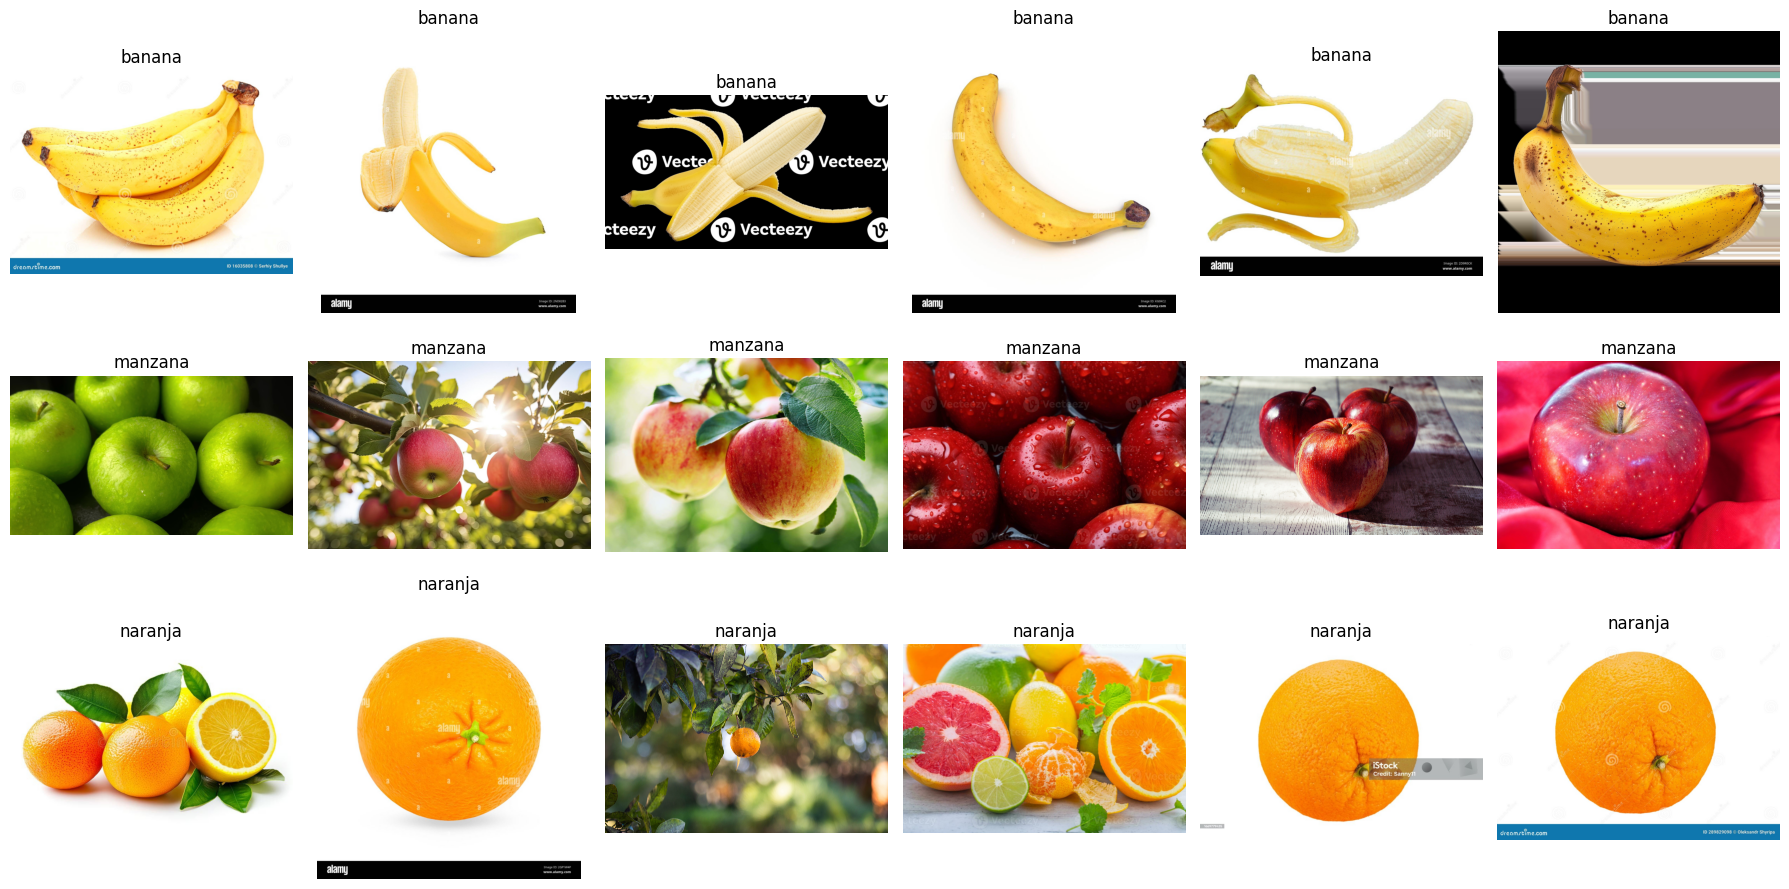

In [14]:
def show_random_images(root, n_per_class=6):
    root = Path(root)
    class_dirs = [p for p in sorted(root.iterdir()) if p.is_dir()]
    fig, axes = plt.subplots(len(class_dirs), n_per_class, figsize=(3*n_per_class, 3*len(class_dirs)))
    if len(class_dirs) == 1:
        axes = np.expand_dims(axes, 0)
    for row, class_dir in enumerate(class_dirs):
        files = list(class_dir.glob("*.jpg"))
        chosen = random.sample(files, min(n_per_class, len(files)))
        for col in range(n_per_class):
            ax = axes[row, col]
            if col < len(chosen):
                img = Image.open(chosen[col])
                ax.imshow(img)
                ax.set_title(class_dir.name)
            ax.axis("off")
    plt.tight_layout()

show_random_images(RAW_DIR)

In [28]:
count_images(RAW_DIR)

{'banana': 99, 'manzana': 101, 'naranja': 105}

### Checkpoint del dataset

Antes de continuar, asegúrate de que:

- cada carpeta contiene imágenes realmente asociadas a su clase;
- no predominan logos, dibujos o texto que revele la etiqueta;
- no hay una diferencia de fondo/estilo demasiado obvia entre clases;
- el número de imágenes por clase es razonablemente balanceado.

Registra aquí el número de imágenes eliminadas y el problema de calidad más frecuente.

  Tuvimos 0 imágenes eliminadas y pensamos que ibamos a obtener imágenes con el mismo fondo pero son fondos distintos lo que nos pude ayudar a que el modelo aprenda a distinguir mejor.

Después de la limpieza, el dataset quedó compuesto por 305 imágenes:

| Clase | Número de imágenes |
|---|---:|
| Banana | 99 |
| Manzana | 101 |
| Naranja | 105 |
| **Total** | **305** |

Las clases están aproximadamente balanceadas: la diferencia entre
la clase con más imágenes y la clase con menos imágenes es de 6.

# 4. Separar train, validation y test — EN CLASE

> **Concepto clave — tres conjuntos, tres funciones**
>
> - **Train:** se utiliza para actualizar los pesos del modelo.
> - **Validation:** se utiliza durante el desarrollo para decidir épocas, `learning_rate`, número de capas a descongelar, etc.
> - **Test:** se reserva para medir el rendimiento final. No debe guiar las decisiones de entrenamiento.

Usaremos **70 % entrenamiento, 15 % validación y 15 % prueba**.

In [15]:
SPLIT_DIR = Path("dataset")

def split_dataset(source_root, destination_root, train_ratio=0.70, val_ratio=0.15, seed=SEED):
    source_root = Path(source_root)
    destination_root = Path(destination_root)
    if destination_root.exists():
        shutil.rmtree(destination_root)
    rng = random.Random(seed)

    for class_dir in sorted(source_root.iterdir()):
        if not class_dir.is_dir():
            continue
        files = list(class_dir.glob("*.jpg"))
        rng.shuffle(files)
        n = len(files)
        n_train = int(n * train_ratio)
        n_val = int(n * val_ratio)
        splits = {
            "train": files[:n_train],
            "validation": files[n_train:n_train+n_val],
            "test": files[n_train+n_val:],
        }
        for split_name, split_files in splits.items():
            target = destination_root / split_name / class_dir.name
            target.mkdir(parents=True, exist_ok=True)
            for src in split_files:
                shutil.copy2(src, target / src.name)

split_dataset(RAW_DIR, SPLIT_DIR)
for split in ["train", "validation", "test"]:
    print(split, count_images(SPLIT_DIR / split))

train {'banana': 69, 'manzana': 70, 'naranja': 73}
validation {'banana': 14, 'manzana': 15, 'naranja': 15}
test {'banana': 16, 'manzana': 16, 'naranja': 17}


### Comprobación conceptual

Explica brevemente: ¿por qué usar repetidamente el conjunto de prueba para escoger épocas, `learning_rate` o capas a descongelar termina contaminando nuestra estimación de desempeño?

R/
El conjunto de prueba debe utilizarse únicamente para evaluar el desempeño final del modelo. Si lo usamos repetidamente para escoger las épocas, el `learning_rate` o las capas que vamos a descongelar, terminamos tomando decisiones basadas en sus resultados. Aunque el modelo no se entrene directamente con esas imágenes, estamos adaptando nuestras decisiones a ellas, por lo que la estimación final puede ser demasiado optimista y dejar de representar qué tan bien funcionará con datos nuevos. Para evitarlo, debemos utilizar el conjunto de entrenamiento para entrenar, el de validación para escoger los hiperparámetros y el conjunto de prueba una sola vez, al final.

# 5. Construir los datasets de Keras — EN CLASE

`image_dataset_from_directory()` construye un `tf.data.Dataset` usando el nombre de las carpetas como clases.

Observa que:

- `train` se mezcla (`shuffle=True`);
- `validation` y `test` mantienen un orden estable;
- todas las imágenes se redimensionan a `224×224` para EfficientNetB0.

In [16]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_ds = keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "train", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=True, seed=SEED)
val_ds = keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "validation", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=False)
test_ds = keras.utils.image_dataset_from_directory(
    SPLIT_DIR / "test", image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="int", shuffle=False)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)
print(class_names)

Found 212 files belonging to 3 classes.
Found 44 files belonging to 3 classes.
Found 49 files belonging to 3 classes.
['banana', 'manzana', 'naranja']


# 6. Primer modelo: transfer learning — EN CLASE

Usaremos **EfficientNetB0** preentrenada en ImageNet. Primero congelaremos completamente la red base y entrenaremos solo una nueva cabeza de clasificación.

> **Concepto clave — Data augmentation**
>
> `RandomFlip`, `RandomRotation` y `RandomZoom` generan variaciones plausibles durante el entrenamiento. No crean información nueva, pero ayudan a que el modelo dependa menos de detalles accidentales de las imágenes descargadas.

> **Concepto clave — GlobalAveragePooling2D**
>
> En lugar de aplanar todos los mapas de características con `Flatten`, `GlobalAveragePooling2D` resume cada canal en un solo valor. Así reducimos mucho el número de parámetros de la cabeza de clasificación.

In [17]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
], name="augmentation")

base_model = keras.applications.EfficientNetB0(
    include_top=False, weights="imagenet", input_shape=(*IMG_SIZE, 3))
base_model.trainable = False

inputs = keras.Input(shape=(*IMG_SIZE, 3))
x = data_augmentation(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
model = keras.Model(inputs, outputs)
model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,053,414 (15.46 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

## TODO 3 — EN CLASE: entrena la cabeza de clasificación

La base EfficientNet está congelada. Tu trabajo es configurar y entrenar la nueva cabeza.

> **Concepto clave — EarlyStopping**
>
> `EarlyStopping` detiene el entrenamiento cuando `val_loss` deja de mejorar. Con `restore_best_weights=True`, Keras recupera los pesos de la mejor época observada en validación.

Antes de ejecutar, escribe una predicción corta:

- ¿esperas que `train_accuracy` suba rápidamente?
- ¿qué señal en las curvas indicaría overfitting?

Completa únicamente los espacios `TODO` del código siguiente.

**¿Esperas que la accuracy de entrenamiento suba rápidamente?**

Sí, esperamos que aumente relativamente rápido porque EfficientNetB0
ya aprendió características visuales al entrenarse en ImageNet.
Aprovechamos esas características y entrenamos una nueva cabeza
para distinguir bananas, manzanas y naranjas, mientras mantenemos
congelada la base. Sin embargo, esto dependerá de la calidad y
dificultad de nuestras imágenes.

**¿Qué señal en las curvas indicaría overfitting?**

Una señal sería que la pérdida de entrenamiento siguiera disminuyendo
mientras la pérdida de validación aumentara de forma sostenida.
Esto indicaría que el modelo está mejorando sobre los datos usados
para entrenar, pero está empeorando sobre los de validación.
También podría observarse una diferencia creciente entre la accuracy
de entrenamiento y la de validación.

In [18]:
# TODO 3 — EN CLASE: completa la configuración de entrenamiento

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),  # 1e-3
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],                                      # "accuracy"
)

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",                  # "val_loss"
    patience=2,
    restore_best_weights=True,
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[early_stopping],
)

Epoch 1/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 42s 3s/step - accuracy: 0.6132 - loss: 0.9315 - val_accuracy: 0.9318 - val_loss: 0.6586
Epoch 2/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 14s 2s/step - accuracy: 0.9198 - loss: 0.5661 - val_accuracy: 1.0000 - val_loss: 0.3974
Epoch 3/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 20s 2s/step - accuracy: 0.9717 - loss: 0.3663 - val_accuracy: 1.0000 - val_loss: 0.2523
Epoch 4/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 14s 2s/step - accuracy: 0.9764 - loss: 0.2413 - val_accuracy: 1.0000 - val_loss: 0.1751
Epoch 5/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 22s 2s/step - accuracy: 0.9953 - loss: 0.1685 - val_accuracy: 1.0000 - val_loss: 0.1298
Epoch 6/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 20s 2s/step - accuracy: 0.9953 - loss: 0.1410 - val_accuracy: 1.0000 - val_loss: 0.1003
Epoch 7/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 19s 2s/step - accuracy: 0.9953 - loss: 0.1190 - val_accuracy: 1.0000 - val_loss: 0.0819
Epoch 8/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 20s 2s/step - accuracy: 0.9953 - loss: 0.0996 - val_accuracy: 1.0000 - val_loss: 0.0696
Epoch 9/

### Curvas de aprendizaje — EN CLASE si el tiempo lo permite

Grafica `accuracy`, `val_accuracy`, `loss` y `val_loss`.

Si el tiempo de clase termina antes, **puedes completar estas curvas en casa**.  
Lo obligatorio antes de salir es haber entrenado el primer modelo y tener sus métricas de entrenamiento/validación.

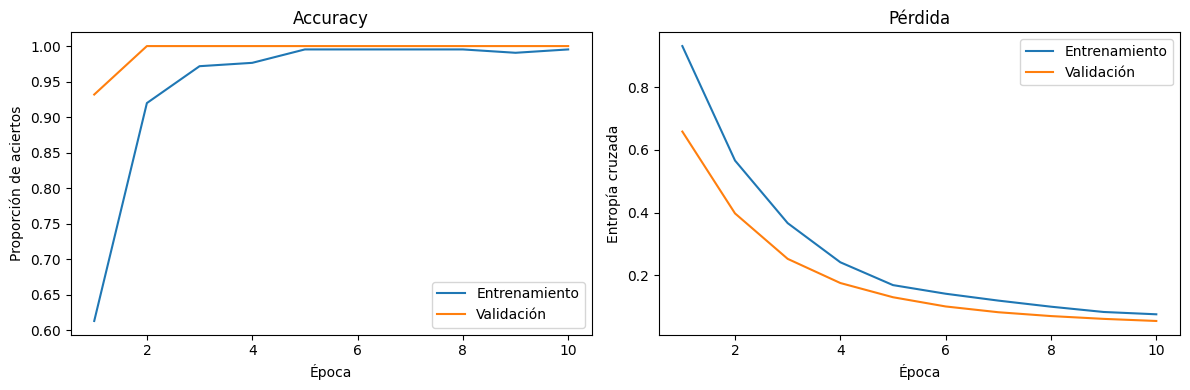

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
epochs = range(1, len(history.history["loss"]) + 1)

# Accuracy
axes[0].plot(
    epochs, history.history["accuracy"], label="Entrenamiento"
)
axes[0].plot(
    epochs, history.history["val_accuracy"], label="Validación"
)
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Proporción de aciertos")
axes[0].legend()

# Pérdida
axes[1].plot(
    epochs, history.history["loss"], label="Entrenamiento"
)
axes[1].plot(
    epochs, history.history["val_loss"], label="Validación"
)
axes[1].set_title("Pérdida")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Entropía cruzada")
axes[1].legend()

plt.tight_layout()
plt.show()

La accuracy de entrenamiento aumentó aproximadamente del 61 % a
casi el 100 %. La accuracy de validación alcanzó el 100 % desde la
segunda época y se mantuvo en ese valor.

Las pérdidas de entrenamiento y validación disminuyeron durante
las diez épocas. No se observa una señal clara de sobreajuste:
la pérdida de validación no presenta un aumento sostenido mientras
disminuye la de entrenamiento.

Aunque la accuracy de validación se mantuvo en 100 %, su pérdida
continuó disminuyendo. Esto es posible porque la pérdida considera
las probabilidades asignadas a las clases, mientras que la accuracy
solo cuenta si la clase elegida fue correcta.

Estos resultados muestran un buen desempeño en los conjuntos
evaluados durante el entrenamiento, pero no garantizan el mismo
rendimiento con imágenes nuevas y más difíciles.

# PUNTO DE CONTROL — FIN DEL TRABAJO EN CLASE

Antes de continuar, verifica que tu equipo tenga:

- [ ] 3 clases definidas;
- [ ] términos de búsqueda documentados;
- [ ] imágenes descargadas;
- [ ] dataset inspeccionado y parcialmente limpiado;
- [ ] separación `train / validation / test`;
- [ ] EfficientNetB0 con pesos de ImageNet;
- [ ] backbone congelado;
- [ ] nueva cabeza de clasificación;
- [ ] al menos un entrenamiento completado;
- [ ] `accuracy` y `val_accuracy` reportadas.

## Hasta aquí llega el trabajo de clase.

**No uses todavía el conjunto de test para tomar decisiones.**

---

# PARTE B — TRABAJO EN CASA

A partir de este punto debes completar el análisis de manera autónoma.

Ahora sí vas a:

1. evaluar el modelo en `test`;
2. estudiar la matriz de confusión y métricas por clase;
3. realizar fine-tuning;
4. comparar el modelo congelado contra el modelo ajustado;
5. analizar errores;
6. escribir las conclusiones.

# 7. Evaluación del primer modelo — EN CASA

Ahora sí utilizaremos el conjunto de prueba.

> **Concepto clave — No todo es accuracy**
>
> - **Precision:** de las imágenes que el modelo predijo como una clase, ¿cuántas eran correctas?
> - **Recall:** de las imágenes que realmente pertenecían a una clase, ¿cuántas encontró?
> - **F1:** combina precision y recall.
> - **Matriz de confusión:** muestra qué clases se están confundiendo entre sí.

Guarda esta evaluación: será nuestra línea base antes del fine-tuning.

In [20]:
test_loss_before, test_acc_before = model.evaluate(test_ds, verbose=0)
print(f"Test accuracy antes del fine-tuning: {test_acc_before:.4f}")

Test accuracy antes del fine-tuning: 1.0000


              precision    recall  f1-score   support

      banana      1.000     1.000     1.000        16
     manzana      1.000     1.000     1.000        16
     naranja      1.000     1.000     1.000        17

    accuracy                          1.000        49
   macro avg      1.000     1.000     1.000        49
weighted avg      1.000     1.000     1.000        49



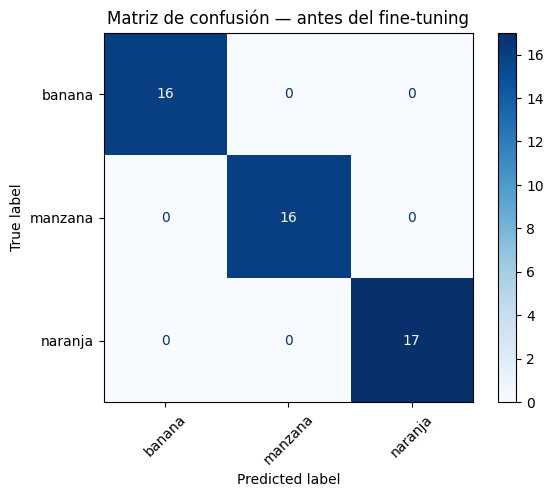

In [21]:
def get_predictions(model, dataset):
    y_true = np.concatenate([y.numpy() for _, y in dataset])
    probabilities = model.predict(dataset, verbose=0)
    y_pred = probabilities.argmax(axis=1)
    return y_true, y_pred, probabilities

y_true, y_pred, probabilities = get_predictions(model, test_ds)
print(classification_report(y_true, y_pred, target_names=class_names, digits=3))
cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names).plot(cmap="Blues", xticks_rotation=45)
plt.title("Matriz de confusión — antes del fine-tuning")
plt.show()

## TODO 4 — EN CASA: interpreta la evaluación

Utilizando `classification_report` y la matriz de confusión, responde:

1. ¿Cuál clase obtuvo mejores resultados?

Las tres clases obtuvieron el mismo desempeño: precision, recall
y F1-score de 1.000 en este conjunto de prueba.

2. ¿Cuál fue la principal confusión?

No se observaron confusiones. Se clasificaron correctamente las
16 imágenes de banana, las 16 de manzana y las 17 de naranja:
49 aciertos de 49 imágenes.

3. ¿La accuracy global oculta algún problema por clase?

En este conjunto no se observan problemas por clase: las métricas
individuales coinciden con la accuracy global del 100 %.
Sin embargo, el conjunto de prueba es pequeño y este resultado
no garantiza un rendimiento perfecto con imágenes nuevas.
También debemos comprobar que no existan imágenes duplicadas
o casi idénticas entre entrenamiento y prueba.

4. ¿Qué cambiarías primero en el dataset antes de cambiar el modelo?

Ampliaría la diversidad de imágenes con fotografías independientes,
distintas condiciones de iluminación, fondos, posiciones y niveles
de madurez. Incluiría casos más difíciles que sigan teniendo una
etiqueta clara, como frutas parcialmente ocultas o pequeñas dentro
de la fotografía.

Además, revisaría posibles duplicados y sesgos entre los conjuntos.
Estas mejoras permitirían evaluar mejor si el modelo aprendió
características de las frutas que se generalizan a imágenes nuevas.

# 8. Fine-tuning — EN CASA

Ahora permitiremos que una pequeña parte de EfficientNet se adapte al nuevo problema.

> **Concepto clave — Fine-tuning**
>
> En la fase anterior, los pesos del backbone no cambiaron. Ahora descongelaremos únicamente una parte final del modelo y la actualizaremos con un **learning rate mucho menor**.

> **Concepto clave — Batch Normalization**
>
> EfficientNet contiene capas `BatchNormalization`, que mantienen estadísticas internas aprendidas durante el entrenamiento. En datasets pequeños conviene mantenerlas congeladas durante fine-tuning para evitar actualizaciones inestables de esas estadísticas.

Después de cambiar qué capas son entrenables, es necesario **recompilar** el modelo.

In [22]:
base_model.trainable = True

# TODO 5 — Decide cuántas capas finales adaptar.
# Empieza con ~20. Puedes justificar otro valor usando validation.
N_UNFROZEN = 20

for layer in base_model.layers[:-N_UNFROZEN]:
    layer.trainable = False

# Mantener Batch Normalization congelado.
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

print(
    "Capas entrenables de la base:",
    sum(layer.trainable for layer in base_model.layers),
    "/",
    len(base_model.layers),
)

Capas entrenables de la base: 15 / 238


Seleccionamos las últimas 20 capas de EfficientNetB0 como región
candidata para el ajuste fino, manteniendo congeladas las anteriores.
Buscamos adaptar las características de la parte final de la red
a la clasificación de nuestras frutas, conservando la mayor parte
del conocimiento preentrenado.

Dentro de esas últimas capas, mantenemos congeladas las capas
BatchNormalization. Por tanto, seleccionar las últimas 20 capas
no significa que queden exactamente 20 capas entrenables.

Reducimos la tasa de aprendizaje de 1e-3 a 1e-5, es decir,
100 veces, para realizar ajustes más pequeños sobre los pesos
preentrenados. La cabeza de clasificación también sigue entrenándose.

El valor 20 se utiliza como punto de partida sugerido por el taller.
No afirmamos que sea la mejor elección, porque para establecerlo
sería necesario comparar alternativas utilizando validación.

## TODO 5 — EN CASA: realiza fine-tuning

Recompila y continúa el entrenamiento.

Usa como punto de partida:

- `Adam(learning_rate=1e-5)`;
- `SparseCategoricalCrossentropy`;
- `accuracy`;
- entre **3 y 8 épocas** adicionales;
- `EarlyStopping` sobre `val_loss`.

Tu decisión principal aquí es **cuántas capas descongelar**. Justifícala usando el desempeño de validación, no el conjunto de prueba.

In [23]:
# TODO 5 — EN CASA: completa el fine-tuning

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),  # 1e-5
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

early_stopping_ft = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True,
)

history_ft = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,  # entre 3 y 8
    callbacks=[early_stopping_ft],
)

Epoch 1/5
7/7 ━━━━━━━━━━━━━━━━━━━━ 27s 3s/step - accuracy: 0.9906 - loss: 0.0747 - val_accuracy: 1.0000 - val_loss: 0.0476
Epoch 2/5
7/7 ━━━━━━━━━━━━━━━━━━━━ 18s 2s/step - accuracy: 0.9953 - loss: 0.0683 - val_accuracy: 1.0000 - val_loss: 0.0420
Epoch 3/5
7/7 ━━━━━━━━━━━━━━━━━━━━ 20s 2s/step - accuracy: 0.9906 - loss: 0.0604 - val_accuracy: 1.0000 - val_loss: 0.0373
Epoch 4/5
7/7 ━━━━━━━━━━━━━━━━━━━━ 24s 2s/step - accuracy: 1.0000 - loss: 0.0514 - val_accuracy: 1.0000 - val_loss: 0.0333
Epoch 5/5
7/7 ━━━━━━━━━━━━━━━━━━━━ 19s 2s/step - accuracy: 0.9953 - loss: 0.0407 - val_accuracy: 1.0000 - val_loss: 0.0299


# 9. Comparación final — EN CASA

Compara el desempeño del mismo sistema **antes y después** del fine-tuning.

Una mejora pequeña también puede ser válida. Si el resultado empeora, no significa que el experimento “salió mal”: debes interpretar por qué pudo ocurrir.

In [24]:
test_loss_after, test_acc_after = model.evaluate(test_ds, verbose=0)
print(f"Antes del fine-tuning  : {test_acc_before:.4f}")
print(f"Después del fine-tuning: {test_acc_after:.4f}")
print(f"Diferencia              : {test_acc_after-test_acc_before:+.4f}")

Antes del fine-tuning  : 1.0000
Después del fine-tuning: 1.0000
Diferencia              : +0.0000


              precision    recall  f1-score   support

      banana      1.000     1.000     1.000        16
     manzana      1.000     1.000     1.000        16
     naranja      1.000     1.000     1.000        17

    accuracy                          1.000        49
   macro avg      1.000     1.000     1.000        49
weighted avg      1.000     1.000     1.000        49



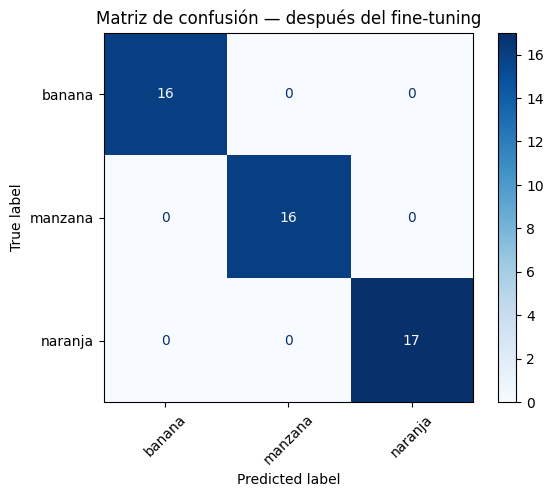

In [25]:
y_true_ft, y_pred_ft, probabilities_ft = get_predictions(model, test_ds)
print(classification_report(y_true_ft, y_pred_ft, target_names=class_names, digits=3))
cm_ft = confusion_matrix(y_true_ft, y_pred_ft)
ConfusionMatrixDisplay(confusion_matrix=cm_ft, display_labels=class_names).plot(cmap="Blues", xticks_rotation=45)
plt.title("Matriz de confusión — después del fine-tuning")
plt.show()

In [30]:
print(f"Accuracy antes:   {test_acc_before:.4f}")
print(f"Accuracy después: {test_acc_after:.4f}")
print(f"Loss antes:       {test_loss_before:.6f}")
print(f"Loss después:     {test_loss_after:.6f}")

Accuracy antes:   1.0000
Accuracy después: 1.0000
Loss antes:       0.047179
Loss después:     0.025316


| Métrica | Antes del fine-tuning | Después del fine-tuning |
|---|---:|---:|
| Accuracy de test | 100 % | 100 % |
| Pérdida de test | 0.047179 | 0.025316 |

El fine-tuning no cambió la accuracy: ambos modelos clasificaron
correctamente las 49 imágenes del conjunto de prueba.

La pérdida disminuyó aproximadamente un 46.3 %. Como usamos
entropía cruzada, esto indica que, en conjunto, el modelo asignó
mayor probabilidad a las etiquetas correctas después del ajuste.

Por tanto, observamos una mejora en la pérdida, pero no en el
número de aciertos. Esto no demuestra por sí solo una mejor
generalización a otros datos ni que las probabilidades estén
mejor calibradas.

# 10. Analiza los errores — EN CASA

Una métrica no explica por qué falla un modelo. Debes inspeccionar ejemplos clasificados incorrectamente.

In [26]:
def show_mistakes(dataset, model, class_names, max_images=12):
    mistakes = []
    for images, labels in dataset:
        probs = model.predict(images, verbose=0)
        preds = probs.argmax(axis=1)
        for image, true_label, pred_label, prob in zip(images.numpy(), labels.numpy(), preds, probs):
            if true_label != pred_label:
                mistakes.append((image.astype("uint8"), int(true_label), int(pred_label), float(prob[pred_label])))
    random.shuffle(mistakes)
    mistakes = mistakes[:max_images]
    if not mistakes:
        print("No se encontraron errores en este conjunto.")
        return
    cols = 4
    rows = int(np.ceil(len(mistakes)/cols))
    plt.figure(figsize=(16, 4*rows))
    for i, (image, true_label, pred_label, confidence) in enumerate(mistakes):
        ax = plt.subplot(rows, cols, i+1)
        ax.imshow(image)
        ax.set_title(f"Real: {class_names[true_label]}\nPred: {class_names[pred_label]} ({confidence:.2f})")
        ax.axis("off")
    plt.tight_layout()

show_mistakes(test_ds, model, class_names)

No se encontraron errores en este conjunto.


## TODO 6 — EN CASA: análisis de errores y conclusiones

Selecciona al menos **5 errores** del modelo y analiza su causa probable.

| Imagen/error | Clase real | Predicción | Causa probable | ¿Cómo lo mejorarías? |
|---|---|---|---|---|
| 1 | | | | |
| 2 | | | | |
| 3 | | | | |
| 4 | | | | |
| 5 | | | | |

Posibles causas: imagen ambigua, etiqueta incorrecta, objeto pequeño, oclusión, fondo engañoso, clase visualmente similar, mala calidad, sesgo del dataset o error razonable del modelo.

Después, escribe una conclusión breve respondiendo:

1. ¿Qué aprendiste al construir el dataset?
2. ¿Cuál fue el principal problema de calidad?
3. ¿Cuánto cambió el desempeño después del fine-tuning?
4. ¿El fine-tuning ayudó? ¿Por qué crees que sí o no?
5. ¿Qué mejorarías primero: datos, entrenamiento o arquitectura?

**Análisis de errores**

No se encontraron imágenes mal clasificadas en las 49 imágenes
del conjunto de prueba después del fine-tuning. Por tanto, no fue
posible seleccionar cinco errores reales para completar la tabla.

Este resultado se limita al conjunto evaluado y no demuestra que
el modelo esté libre de errores con otras imágenes. El tamaño
reducido del test y su posible similitud con los datos de entrenamiento
limitan las conclusiones sobre generalización.

Como evaluación adicional, proponemos recopilar fotografías
independientes con iluminación variable, fondos complejos y oclusión
parcial, manteniendo una clase real claramente identificable.

1. **¿Qué aprendimos al construir el dataset?**

Aprendimos que descargar imágenes no basta: debemos comprobar
que puedan abrirse, que correspondan a su etiqueta y que tengan
diversidad suficiente. El dataset final contiene 305 imágenes:
99 de banana, 101 de manzana y 105 de naranja.

2. **¿Cuál fue el principal problema de calidad?**

No documentamos un problema de calidad predominante en la revisión
realizada. Esto no descarta problemas que hayan pasado inadvertidos,
como imágenes casi duplicadas o asociaciones entre fondos y clases.

3. **¿Cuánto cambió el desempeño después del fine-tuning?**

La accuracy de test permaneció en 100 %. La pérdida disminuyó
de 0.047179 a 0.025316, una reducción aproximada del 46.3 %.

4. **¿El fine-tuning ayudó?**

Mejoró la pérdida en el conjunto de prueba, pero no aumentó los
aciertos, porque el modelo inicial ya clasificaba correctamente
las 49 imágenes. Necesitamos una evaluación independiente más
amplia para determinar si esa mejora se mantiene.

5. **¿Qué mejoraríamos primero?**

Priorizaríamos los datos: ampliaríamos su diversidad y revisaríamos
duplicados y posibles sesgos. Esto permitiría evaluar las limitaciones
del modelo antes de cambiar la arquitectura.

**Transfer learning con base congelada**

Utilizamos EfficientNetB0 con pesos previamente aprendidos en
ImageNet para extraer características visuales. Conservamos
congelados los pesos de la base y entrenamos una nueva cabeza
de clasificación para distinguir bananas, manzanas y naranjas.
El conocimiento inicial procede del entrenamiento en ImageNet.

**Fine-tuning**

Partimos del modelo anterior y permitimos actualizar una parte
final de la base, además de seguir entrenando la cabeza.
Seleccionamos las últimas 20 capas como candidatas, pero quedaron
15 capas habilitadas para entrenamiento porque mantuvimos
congeladas las capas BatchNormalization.

Recompilamos el modelo y redujimos la tasa de aprendizaje
de 0.001 a 0.00001 para ajustar los pesos preentrenados
con pasos más pequeños.

**Entrenar una CNN desde cero**

Construiríamos una red sin cargar los pesos aprendidos en ImageNet.
Los parámetros entrenables partirían de su inicialización y se
ajustarían usando nuestro conjunto de entrenamiento.

Con solo 305 imágenes, aprender características útiles desde cero
puede resultar más difícil y presentar mayor riesgo de sobreajuste
que aprovechar una red preentrenada.

# Extensión opcional — Prueba con una imagen externa

Busca una imagen que **no esté en tu dataset** y prueba el modelo. Esta parte no cuenta como un TODO principal, pero sirve como comprobación cualitativa de generalización.

In [27]:
# OPCIONAL
# EXTERNAL_IMAGE_URL = "https://..."
# response = requests.get(EXTERNAL_IMAGE_URL, timeout=10)
# response.raise_for_status()
# img = Image.open(io.BytesIO(response.content)).convert("RGB")
# img_resized = img.resize(IMG_SIZE)
# x = np.array(img_resized, dtype="float32")[None, ...]
# p = model.predict(x, verbose=0)[0]
# plt.imshow(img)
# plt.axis("off")
# plt.title(f"{class_names[p.argmax()]} — confianza {p.max():.2f}")
# plt.show()

# 🏠 Cierre conceptual — ENTREGA

Como parte del **TODO 6**, explica con tus propias palabras la diferencia entre:

- **feature extraction / transfer learning con base congelada**;
- **fine-tuning**;
- **entrenar una CNN desde cero**.

No describas solo el código. Explica **qué parámetros se están aprendiendo y de dónde viene el conocimiento inicial**.

# Reto opcional

Elige **uno**:

**A. Más datos:** duplica el número de imágenes manteniendo el modelo igual.  
**B. Otro backbone:** prueba MobileNetV3, ResNet50 o EfficientNetV2B0.  
**C. Dataset difícil:** agrega una cuarta clase visualmente parecida.  
**D. Ablation:** entrena sin `data_augmentation` y compara.

Cambia **una sola variable a la vez**.

# ✅ Checklist de entrega

Antes de entregar verifica:

### Evidencia del trabajo en clase
- [ ] Problema y clases definidos.
- [ ] Dataset construido y revisado.
- [ ] Train / validation / test creados.
- [ ] Primer modelo con backbone congelado entrenado.

### Trabajo en casa
- [ ] Evaluación sobre test.
- [ ] Matriz de confusión.
- [ ] Precision / recall / F1 interpretados.
- [ ] Fine-tuning ejecutado.
- [ ] Comparación antes vs. después del fine-tuning.
- [ ] Al menos 5 errores analizados.
- [ ] Conclusión final escrita.

### Opcional
- [ ] Imagen externa.
- [ ] Experimento adicional / reto.

# Rúbrica sugerida

| Componente | Peso |
|---|---:|
| TODO 1 — Problema y estrategia de búsqueda | 10% |
| TODO 2 — Construcción, inspección y limpieza del dataset | 20% |
| Split y pipeline de datos | 10% |
| TODO 3 — Transfer learning + curvas | 20% |
| TODO 4 — Evaluación e interpretación | 10% |
| TODO 5 — Fine-tuning y comparación | 15% |
| TODO 6 — Análisis de errores + conclusión conceptual | 15% |
| **Total** | **100%** |